# Notebook 1: Time-Walk Visualization


The purpose of this notebook is to  show that the time of arrival measured by the digitizer (`t_raw`)
depends on the pulse size (time-walk), and understand the other factors affecting it.

Δt = t_raw − t_true
- `t_raw` is the time when the pulse crosses the fixed threshold.
- `t_true` is the true arrival time of the particle .

**Input:** `../data/hits.h5`, made by `src/convert_to_hdf5.py` (one row per event).

**Plots**
1. Δt vs pulse integral
2. Δt vs pixel charge 
3. Δt vs cluster charge
4. Δt vs incidence angle
5. Δt vs position inside the pixel 

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

os.makedirs('plots', exist_ok=True)

INPUT_FILE = '../data/hits.h5'

with h5py.File(INPUT_FILE, 'r') as f:
    t_raw          = np.array(f['t_raw'])
    t_true         = np.array(f['t_true'])
    pulse_integral = np.array(f['pulse_integral'])
    pixel_charge   = np.array(f['pixel_charge'])
    cluster_charge = np.array(f['cluster_charge'])
    cluster_size   = np.array(f['cluster_size'])
    col_frac       = np.array(f['col_frac'])
    row_frac       = np.array(f['row_frac'])
    pixel_col      = np.array(f['pixel_col'])
    angle_deg      = np.array(f['angle_deg'])

print(f"Loaded {len(t_raw)} rows from {INPUT_FILE}")

Loaded 85985 rows from ../data/hits.h5


In [2]:
#Some events deposit charge below digitizer threshold so no pixel crosses the threshold.
#They have NaN in t_raw, pulse_integral and pixel_charge, so they don't have delta_t. They are removed.
valid = ~(np.isnan(t_raw) | np.isnan(pulse_integral) | np.isnan(pixel_charge))
n_dropped = int(np.sum(~valid))
print(f"Dropping {n_dropped} row(s) with NaN t_raw, pulse_integral, pixel_charge "
      f"({100 * n_dropped / len(valid):.2f}%)")

t_raw          = t_raw[valid]
t_true         = t_true[valid]
pulse_integral = pulse_integral[valid]
pixel_charge   = pixel_charge[valid]
cluster_charge = cluster_charge[valid]
cluster_size   = cluster_size[valid]
col_frac       = col_frac[valid]
row_frac       = row_frac[valid]
pixel_col      = pixel_col[valid]
angle_deg      = angle_deg[valid]

delta_t = t_raw - t_true

print(f"delta_t: min={delta_t.min():.1f} ps  max={delta_t.max():.1f} ps  "
      f"mean={delta_t.mean():.1f} ps  std={delta_t.std():.1f} ps")

Dropping 86 row(s) with NaN t_raw, pulse_integral, pixel_charge (0.10%)
delta_t: min=30.0 ps  max=1770.0 ps  mean=290.8 ps  std=83.2 ps


In [3]:
#Δt is about 300 ps as it is dominated by the amplifier rise time and the TDC binning. It is much larger than t_true which is only a few ps.
#Percentiles are used instead of a fixed window to prevent cutting data.
dt_lo, dt_hi = np.percentile(delta_t, [0.5, 99.5])
print(f"delta_t plotting range (0.5-99.5 pct): [{dt_lo:.1f}, {dt_hi:.1f}] ps")

#Δt is quantized on a 10 ps grid based on clock_bin_toa in detector.conf.
#It is checked that 98.2% of values lie within 0.01 ps of a grid line.
#Bins narrower than 10 ps would result in horizontal banding in the histograms below so the bin width is set to 10 ps.
DT_BIN_WIDTH = 10.0  #ps, matches clock_bin_toa
grid_lo = np.floor(dt_lo / DT_BIN_WIDTH) * DT_BIN_WIDTH
grid_hi = np.ceil(dt_hi / DT_BIN_WIDTH) * DT_BIN_WIDTH
dt_bins = np.arange(grid_lo - DT_BIN_WIDTH / 2, grid_hi + DT_BIN_WIDTH, DT_BIN_WIDTH)
n_bins_dt = len(dt_bins) - 1
print(f"Using {n_bins_dt} delta_t bins ({DT_BIN_WIDTH} ps each, centered on data grid)")

delta_t plotting range (0.5-99.5 pct): [70.0, 660.0] ps
Using 61 delta_t bins (10.0 ps each, centered on data grid)


## Plot 1: Time-walk vs pulse integral

`pulse_integral` is the CSA pulse's time integral. It is in arbitrary units and used as a representation of the pulse height.

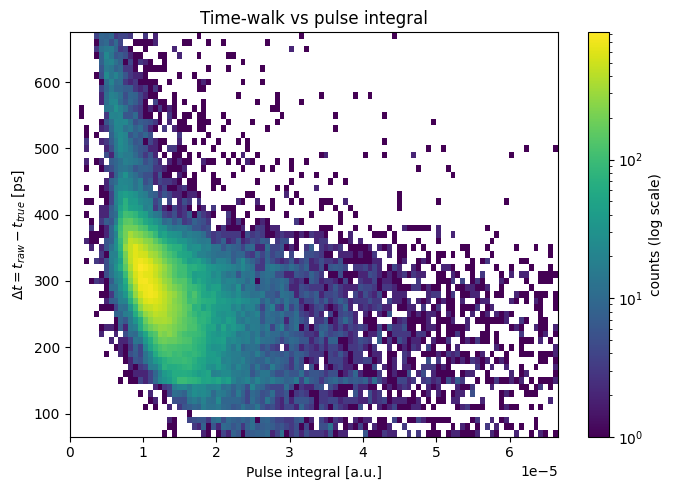

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
pi_hi = np.percentile(pulse_integral, 99.5)
h = ax.hist2d(pulse_integral, delta_t, bins=[100, dt_bins],
              range=[[0, pi_hi], [dt_lo, dt_hi]],
              cmap='viridis', norm=LogNorm())
fig.colorbar(h[3], ax=ax, label='counts (log scale)')
ax.set_xlabel('Pulse integral [a.u.]')
ax.set_ylabel(r'$\Delta t = t_{raw} - t_{true}$ [ps]')
ax.set_title('Time-walk vs pulse integral')
plt.tight_layout()
plt.savefig('plots/delta_t_vs_pulse_integral.pdf', dpi=150)
plt.show()

Δt falls steeply from about 600 ps at <1 a.u. pulse integral and flattens around 100-200 ps for large pulses. The densest region is around Δt= 300 ps. This plot is in alignment with the time-walk effect as it follows a trend of 1/amplitude. A small pulse rises slowly and crosses the threshold later than a larger pulse. As seen from the plot there is a floor of about 100-200 ps. This is a constant delay due to amplifier rise time and TDC offset.
The empty stripe near Δt= 100 ps is likely due to a quantization effect of the 10 ps TDC grid.

## Plot 2: Time-walk vs pixel charge

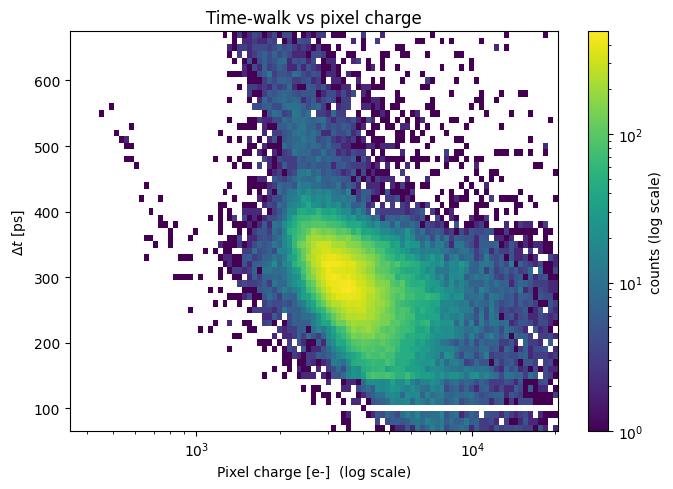

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
q_lo, q_hi = pixel_charge.min(), np.percentile(pixel_charge, 99.5)
x_bins = np.logspace(np.log10(q_lo), np.log10(q_hi), 100)
h = ax.hist2d(pixel_charge, delta_t, bins=[x_bins, dt_bins],
              cmap='viridis', norm=LogNorm())
ax.set_xscale('log')
fig.colorbar(h[3], ax=ax, label='counts (log scale)')
ax.set_xlabel('Pixel charge [e-]  (log scale)')
ax.set_ylabel(r'$\Delta t$ [ps]')
ax.set_title('Time-walk vs pixel charge')
plt.tight_layout()
plt.savefig('plots/delta_t_vs_pixel_charge.pdf', dpi=150)
plt.show()

This plot shows a similar falling curve as the previous plot. In this case Δt is observed against the pixel that fired. At very low charges there are few events with much higher Δt values. The pixel charge determines the pulse height, therefore the physics is the same as previous. For small charges the crossing time is sensitive to noise. Why the plot is divided into branches will be discussed below.

### Why are there two branches?

Coloring each event by `cluster_size`:
- **cluster_size = 1** (blue): one tight band.
- **cluster_size = 2** (green): a second branch at larger Δt for the same
  `pixel_charge`.

This is not due to noise but a real effect. For a charge shared between two pixels, the pixel that fired only detects some part of the signal. Therefore, its pulse is shaped differently compared to a pulse with the same charge that is not shared between pixels. This shows that `cluster_size` and `cluster_charge` should also be considered by the ML model.

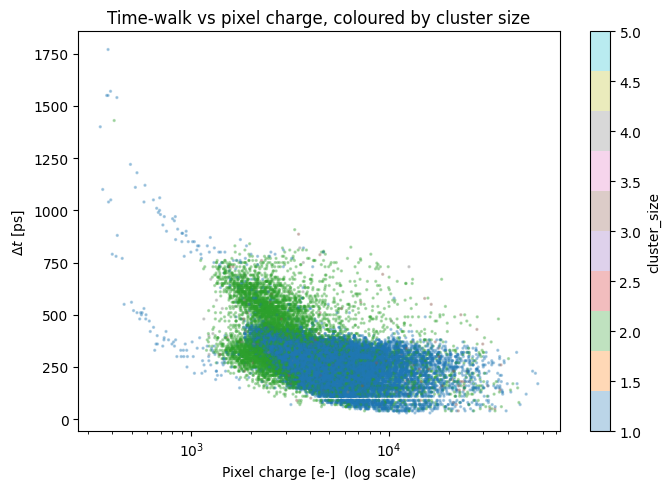

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(pixel_charge, delta_t, c=cluster_size, cmap='tab10', s=2, alpha=0.3)
ax.set_xscale('log')
fig.colorbar(sc, ax=ax, label='cluster_size')
ax.set_xlabel('Pixel charge [e-]  (log scale)')
ax.set_ylabel(r'$\Delta t$ [ps]')
ax.set_title('Time-walk vs pixel charge, coloured by cluster size')
plt.tight_layout()
plt.savefig('plots/delta_t_vs_pixel_charge_by_cluster_size.pdf', dpi=150)
plt.show()

## Plot 3: Time-walk vs cluster charge

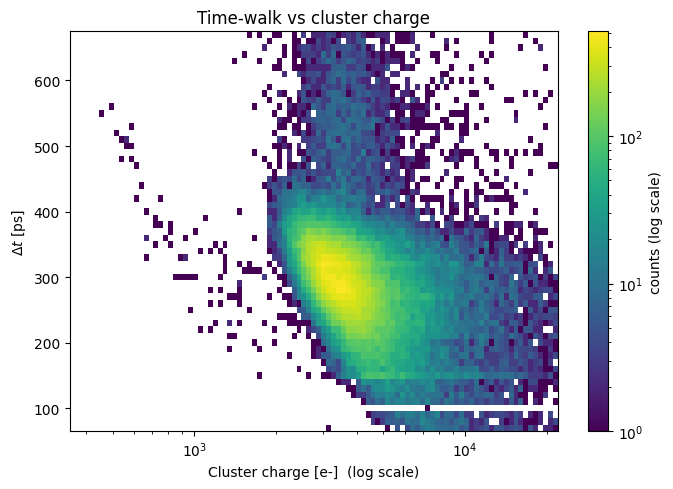

In [7]:
#Charge summed over all pixels in the cluster
fig, ax = plt.subplots(figsize=(7, 5))
q_lo, q_hi = cluster_charge.min(), np.percentile(cluster_charge, 99.5)
x_bins = np.logspace(np.log10(max(q_lo, 1)), np.log10(q_hi), 100)
h = ax.hist2d(cluster_charge, delta_t, bins=[x_bins, dt_bins],
              cmap='viridis', norm=LogNorm())
ax.set_xscale('log')
fig.colorbar(h[3], ax=ax, label='counts (log scale)')
ax.set_xlabel('Cluster charge [e-]  (log scale)')
ax.set_ylabel(r'$\Delta t$ [ps]')
ax.set_title('Time-walk vs cluster charge')
plt.tight_layout()
plt.savefig('plots/delta_t_vs_cluster_charge.pdf', dpi=150)
plt.show()

This plot has a similar shape to Plot 2. Cluster charge is the total deposite cahrge.

## Plot 4: Time-walk residual vs incidence angle

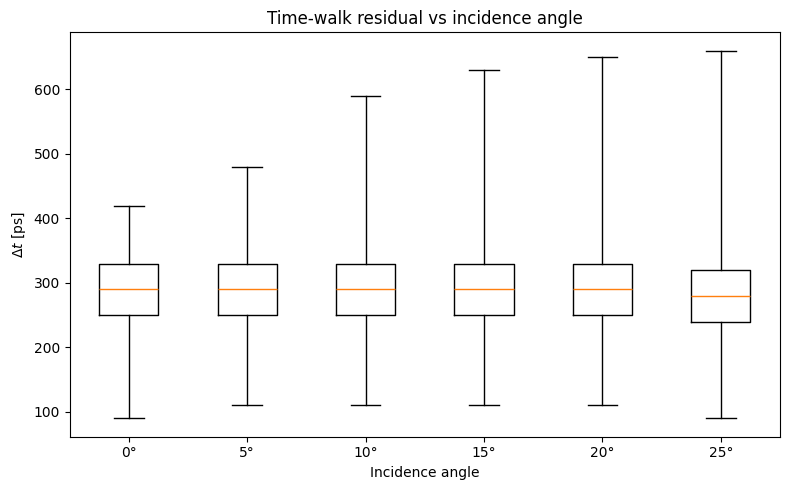

In [8]:
#The box represents 25-75 percentile,the line is the median
angles_present = np.unique(angle_deg)
data_by_angle = [delta_t[angle_deg == a] for a in angles_present]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data_by_angle, labels=[f'{a:.0f}°' for a in angles_present],
           showfliers=False, whis=(1, 99))
ax.set_xlabel('Incidence angle')
ax.set_ylabel(r'$\Delta t$ [ps]')
ax.set_title('Time-walk residual vs incidence angle')
plt.tight_layout()
plt.savefig('plots/delta_t_vs_angle_boxplot.pdf', dpi=150)
plt.show()

The median Δt is around 300 ps for all angles and the box is mostly constant. The 99th percentile represented by the upper line increases with angle. This is because a tilted track crosses the sensor over a longer sideways path therefore more events share charge between pixels. The late tail in the previous plots is due to these events. This indicates that instead of a global correction for all angles, the angle information being taken into account could lead to a better correction.

## Plot 5: Pixel-edge effects on time-walk

`col_frac` is the position inside the pixel along x. 0.5 is the pixel centre and 0 and 1 are the pixel edges.

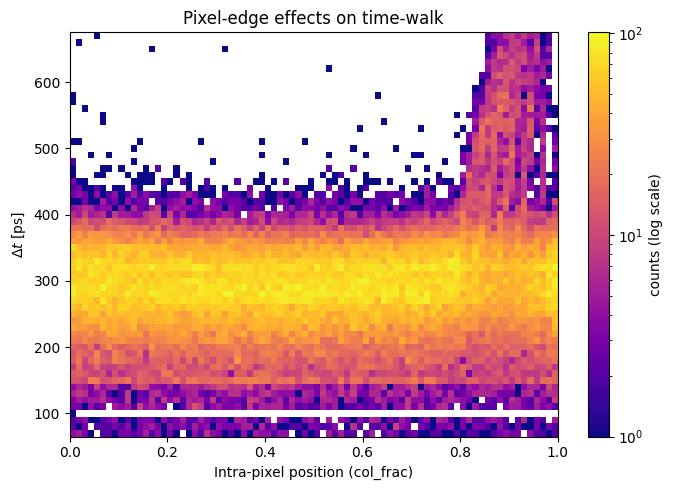

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
h = ax.hist2d(col_frac, delta_t, bins=[80, dt_bins],
              range=[[0, 1], [dt_lo, dt_hi]],
              cmap='plasma', norm=LogNorm())
fig.colorbar(h[3], ax=ax, label='counts (log scale)')
ax.set_xlabel('Intra-pixel position (col_frac)')
ax.set_ylabel(r'$\Delta t$ [ps]')
ax.set_title('Pixel-edge effects on time-walk')
plt.tight_layout()
plt.savefig('plots/delta_t_vs_col_frac.pdf', dpi=150)
plt.show()

For `col_frac` between 0 and about 0.75, Δt is mostly constant around 300 ps. Above 0.8 it rises above 600 ps. This is because near the pixel boundary thr charge is shared with the neighbouring pixels, leading to a smaller pulse in each fired pixel and this increases Δt. This indicates that time-walk has a dependency on where the particle crosses the pixel so `col_frac` might be considered as a factor for the correction with the ML model.

**What causes the edge excess?** 

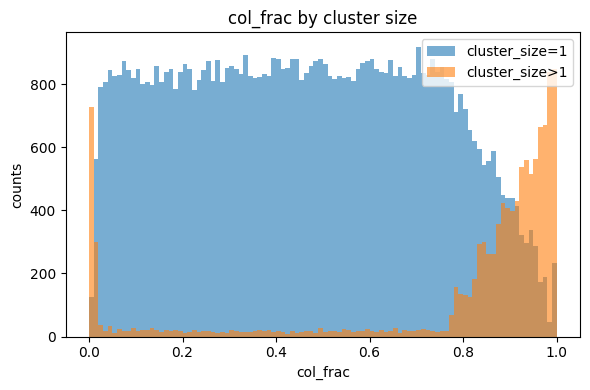

In [10]:
#Histograms of col_frac for single-pixel and multi-pixel events
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(col_frac[cluster_size == 1], bins=100, range=[0, 1], alpha=0.6, label='cluster_size=1')
ax.hist(col_frac[cluster_size > 1], bins=100, range=[0, 1], alpha=0.6, label='cluster_size>1')
ax.legend()
ax.set_xlabel('col_frac')
ax.set_ylabel('counts')
ax.set_title('col_frac by cluster size')
plt.tight_layout()
plt.savefig('plots/col_frac_by_cluster_size.pdf', dpi=150)
plt.show()

From the plot above it can be seen that the pileup near the pixel edges is mostly due to events with cluster size larger than 1. This shows that this effect is really due to charge sharing between neighbouting pixels. Single pixel events which are represented in blue are spread evenly over the pixel and their number decreases near the edge. However, it seems this is only significant for `col_frac` between 0.8 and 1 as there is only a narrow spike at `col_frac=0` Since both edges have the same boundaries, symmetric peaks would be expected. This could be due to `col_frac` being computed at the entry point of the track while the beam is tilted in x. This is explored further below.

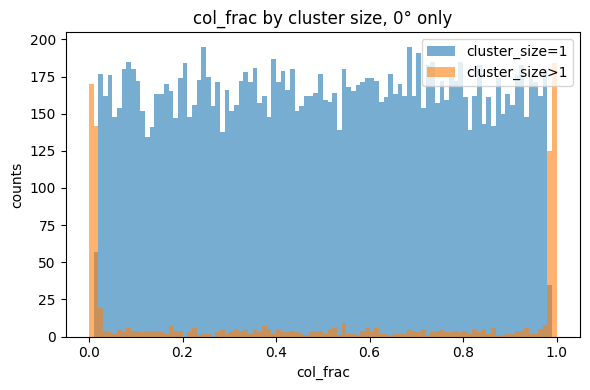

 angle  n_shared  col_frac<0.2  col_frac>0.8
     0       969           397           373
     5      1020           239           629
    10      1587           214          1197
    15      2068           176          1732
    20      2719           202          2352
    25      3140           178          2476


In [11]:
#Histogram for 0 degrees only
m0 = angle_deg == 0   

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(col_frac[m0 & (cluster_size == 1)], bins=100, range=[0, 1],
        alpha=0.6, label='cluster_size=1')
ax.hist(col_frac[m0 & (cluster_size > 1)], bins=100, range=[0, 1],
        alpha=0.6, label='cluster_size>1')
ax.legend()
ax.set_xlabel('col_frac')
ax.set_ylabel('counts')
ax.set_title('col_frac by cluster size, 0° only')
plt.tight_layout()
plt.savefig('plots/col_frac_by_cluster_size_0deg.pdf', dpi=150)
plt.show()

#Number of shared events in both edges for each angle
print(f"{'angle':>6}{'n_shared':>10}{'col_frac<0.2':>14}{'col_frac>0.8':>14}")
for a in np.unique(angle_deg):
    shared = (angle_deg == a) & (cluster_size > 1)
    left  = int(np.sum(shared & (col_frac < 0.2)))
    right = int(np.sum(shared & (col_frac > 0.8)))
    print(f"{a:>6.0f}{int(shared.sum()):>10}{left:>14}{right:>14}")

At 0° the charge sharing is symmetric while for larger angles the right edge events becomes dominant.This confirms that the beam tilt and `col_frac` being computed at the entry point is the reason for this asymmetry and the angle should be considered in the ML model.